# 12. KODEX 200 (069500) CUSUM 연속성 · 변화점 · SVR 통제실험 (2020–2025)

**연구 질문.** KODEX 200 의 실제 가격·변동성 변화에 대해, 어떤 CUSUM 구조와 SVR 학습 정책이 새로운 정보를 주는가? 그 정보는 Autoencoder 의 연속형 입력으로 넘길 가치가 있는가?

- 계약 `12-lock-1` (결과 전 동결) → `12-lock-2` (귀무 DGP 적합 구간만 2019 → 2019–2020, 퇴화한 N0 귀무 교체).
- 한 번에 하나만 바꾼다 (등록 464 실험, 자동 OFAT 검사 위반 0, 상호작용 6 은 따로 표시).
- **관측 판정과 합성 판정은 별개다.** 관측 잔차는 모든 SVR 파이프라인에서 귀무 부적합이라 관측 p 값은 확증용이 아니다 (서술만).
- 비유의·결측·귀무 부적합 날의 통계량도 원장에 전부 남긴다 (681,999 행 · 명세 §3.1 최소 필드 57/57 · §3.2 데이터셋 9종).

In [1]:
# 새 커널 첫 셀: BLAS 스레드를 NumPy 로드 전에 1로 고정해 결과를 결정적으로 만든다.
import os  # 환경변수 설정
import sys  # 인터프리터·모듈 경로 확인
from pathlib import Path  # 저장소 상대 경로

for key in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):  # 네 BLAS 계열 변수
    os.environ[key] = "1"  # 다중 스레드 합산 순서에 따른 비트 차이를 막는다
assert "numpy" not in sys.modules, "새 커널에서 첫 셀부터 실행해야 합니다"  # 숨은 커널 상태 금지
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs/t21_k200_cusum_controlled_v1.json").is_file())  # 저장소 루트 탐색
sys.path.insert(0, str(ROOT / "src"))  # 이 작업트리의 r2h 패키지를 우선 사용

import hashlib  # 파일 지문
import importlib.metadata as metadata  # 설치 패키지 버전 조회
import json  # 설정·캡션
import platform  # Python 버전

import matplotlib  # 그림 백엔드
matplotlib.use("Agg")  # 화면 없이 파일로 저장
import numpy as np  # 수치 배열
import pandas as pd  # 결과표
from IPython.display import Image, Markdown, display  # 표·그림·문단 출력
import matplotlib.pyplot as plt  # 그림 기본 설정
from matplotlib import font_manager  # 한글 글꼴 등록

FONT_FILE = Path("/usr/share/fonts/truetype/nanum/NanumGothic.ttf")  # 한글 도판용 나눔고딕
assert FONT_FILE.is_file(), "한글 도판 렌더링을 위한 나눔고딕 파일이 없습니다"  # 글꼴 없으면 중단
font_manager.fontManager.addfont(str(FONT_FILE))  # matplotlib 글꼴 목록에 등록
plt.rcParams["font.family"] = font_manager.FontProperties(fname=str(FONT_FILE)).get_name()  # 한글 글꼴 사용
plt.rcParams["axes.unicode_minus"] = False  # 음수 기호 깨짐 방지

# 11번과 같은 고정 환경이어야 한다 (user-site 차단 포함).
EXPECTED_ENV = {"python": "3.12.3", "numpy": "2.5.4", "pandas": "3.0.6", "scipy": "1.18.1", "matplotlib": "3.11.2", "scikit-learn": "1.9.1"}  # 고정 환경
ACTUAL_ENV = {"python": platform.python_version(), **{k: metadata.version(k) for k in ("numpy", "pandas", "scipy", "matplotlib", "scikit-learn")}}  # 실제 커널
assert ACTUAL_ENV == EXPECTED_ENV, f"실행 환경 불일치: {ACTUAL_ENV}"  # 버전 불일치는 재현 실패
assert ".local" not in np.__file__, np.__file__  # user-site 패키지 차단
pd.set_option("display.width", 220)  # 표 줄바꿈 완화
pd.set_option("display.max_columns", 40)  # 열 생략 완화
pd.set_option("display.max_rows", 80)  # 행 생략 완화

from r2h.k200_controlled import figures as F  # 12번 그림
from r2h.k200_controlled import report as RP  # 12번 계산·결과 조립

assert Path(sys.modules["r2h"].__file__).resolve().is_relative_to((ROOT / "src").resolve())  # 다른 트리의 r2h 금지
BASE = ROOT / "research/k200_cusum_controlled_12"  # 12번 산출물 폴더
RES = BASE / "results"  # 결과표
FIGDIR = BASE / "figures"  # 그림 (PNG 320dpi + SVG)


def sha(p):  # 파일 SHA256
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()  # 바이트 단위 지문


def preview(path, width=1100):  # 노트북 용량을 줄이는 축소 미리보기 (원본은 figures/)
    from io import BytesIO  # 메모리 버퍼
    from PIL import Image as PILImage  # 이미지 축소
    im = PILImage.open(path)  # 320dpi 원본
    im.thumbnail((width, width * 3))  # 가로 1100px 이하로 축소
    buf = BytesIO()  # 출력 버퍼
    im.save(buf, format="PNG", optimize=True)  # PNG 로 다시 저장
    return buf.getvalue()  # 바이트 반환


# 계약(lock-1·lock-2)·설정 동결 지문 — 파일 이름별 마지막 기록이 현재 파일과 같아야 한다.
FREEZE = {}  # 파일 이름 → 마지막 지문 (lock-2 가 설정을 다시 동결)
for line in (BASE / "CONTRACT_FREEZE_SHA256.txt").read_text().splitlines():  # 동결 기록 (시간순)
    digest, name = line.split(maxsplit=1)  # 해시·경로
    FREEZE[Path(name).name] = digest  # 같은 이름은 나중 기록이 우선
CURRENT = {"RESEARCH_CONTRACT.md": BASE / "RESEARCH_CONTRACT.md", "RESEARCH_CONTRACT_LOCK2.md": BASE / "RESEARCH_CONTRACT_LOCK2.md", "t21_k200_cusum_controlled_v1.json": ROOT / "configs/t21_k200_cusum_controlled_v1.json"}  # 검사 대상
assert all(sha(p) == FREEZE[k] for k, p in CURRENT.items()), "동결 계약·설정 변경"  # 결과 계산 전 동결본과 같아야 한다
# 00–11 보호 파일 지문 (12번 시작 시점 기록) — 실행 전후 모두 같아야 한다 (G8).
PROT = [line.split(maxsplit=1) for line in (BASE / "evidence/PROTECTED_SHA256.txt").read_text().splitlines()]  # (해시, 경로)
bad = [p for h, p in PROT if sha(ROOT / p) != h]  # 바뀐 보호 파일
assert not bad, f"보호 파일 변경: {bad[:5]}"  # 기존 연구는 읽기만
print("작업트리:", ROOT, "| 보호 파일", len(PROT), "개 불변 | 환경", ACTUAL_ENV)  # 검증 요약

작업트리: /home/sieg/projects-wsl/hongik_univ_26_2/SA/1019/R2H_K200_CUSUM_12 | 보호 파일 651 개 불변 | 환경 {'python': '3.12.3', 'numpy': '2.5.4', 'pandas': '3.0.6', 'scipy': '1.18.1', 'matplotlib': '3.11.2', 'scikit-learn': '1.9.1'}


## 0. 실험 설계

| 축 | 부모 | 바꾼 것 | 비고 |
|---|---|---|---|
| 기준선 | — | B0 연초 초기화 → **B1 연도 관통** (앵커) | SVR 정책 A · 연간 확장형 · w=60 |
| E1 | B1 | 초기화 일정 9종 (반년·2년·3년·252·504·연초 위약 이동) | 잔차 재사용 |
| E2 | B1 | 창 20·30·120·252 | |
| E3 | B1 | Page 상·하·양방향 · 2020–2025 사후 · 원수익률 CoS | 공식이 다르면 임계값을 새로 보정 |
| E4·E5 | B1 | 변화점 P·V·M·K × q(0.95·0.99) × 불응기(0·10·20) 로 초기화 + 같은 횟수 위약 | 효과일 t+1 |
| E6–E10 | B1 | 학습창 252·504·756 · 재학습 63·21일 · 변화점 재학습 · 유예 20·60 · 적응형 | 새 SVR 적합이 필요할 때만 |
| E11 | B1 | 임계 보정: 점근·정규 MC·사전 iid·사전 블록 vs GARCH-t 전체 파이프라인 | |

**오경보 부담.** 모든 비교는 같은 α — 귀무에서 '달력연도 블록(2021–2025)마다 1일 이상 경보' 확률 — 로 맞춘다. 귀무 N1 = 2019–2020 으로 적합한 GARCH(1,1)-t (α 0.129, β 0.815, ν 7.06) 를 실제 달력에 모의하고, 경로마다 SVR 재적합·변화점·초기화를 포함한 **전체 파이프라인**을 다시 돌린다 (보정 1000 · 홀드아웃 500 · 시나리오 13 × 200).

In [2]:
# 관측 계산 전부: 069500 수익률 → SVR 정책 10종 → 실험 464종 원시 통계량 → N1 귀무표 부착 → 원장·결과표·감사.
# 합성·귀무 MC(약 3.6시간)는 outputs/t21/mc/ 의 저장 배열을 읽는다 (Git 제외, 해시는 RELEASE_MANIFEST 에).
R = RP.run(ROOT, ROOT / "outputs/t21/calib_n1", ROOT / "outputs/t21/mc/n1_null", RES)  # 결과는 results/ 에 결정적으로 쓴다
T = R["tables"]  # 결과표 dict
OB = R["ob"]  # 관측 계산 객체
CAP = F.Figures12(R, ROOT).make_all()  # 그림 전부 다시 그리고 캡션 수치를 받는다
print("결과 CSV", len(R["written"]), "개 | 원장 행", R["ledger_rows"], "| 실험", len(OB.reg), "| SVR 적합", OB.n_fits, "회")  # 실행 요약

/home/sieg/projects-wsl/hongik_univ_26_2/SA/1019/R2H_K200_CUSUM_12/src/r2h/k200_controlled/report.py:85: RuntimeWarning: Mean of empty slice
  "random_mean": np.nanmean(vr), "random_q95": np.nanquantile(vr, 0.95),
/home/sieg/projects-wsl/hongik_univ_26_2/SA/1012_Annual_SVR–GARCH-CUSUM/R2H/.venv/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1573: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


findfont: Failed to find font weight bold for NanumGothic, now using 600.


결과 CSV 19 개 | 원장 행 681999 | 실험 464 | SVR 적합 110 회


## 1. 기준선 — B0 재현(08 W3 대조)과 B1 연도 관통

**해석 — 기준선.**
- B0 는 08 W3 `run_pipeline` 의 069500 정책 A 와 잔차·예측분산·CUSUM 이 **바이트 동일**하다 (2021–2025 유효 930일 · NA 295일 · 최대 T 1.3013). 12번의 모든 결과는 이 재현 위에 있다 (G0 — 아래 표 `w3_reproduction_check.csv` 를 이 실행에서 다시 계산한다. 11번도 같은 W3 요약을 72/72 재현했다).
- B1 은 연도 경계에서 창을 끊지 않는다. 둘 다 유효한 날의 T 는 **정확히 같고**, B1 은 매년 첫 59일을 채워 유효일이 1,119 → 1,414 로 늘어난다. 연초 초기화는 통계량을 바꾸지 않고 **커버리지만** 바꾼다 (`COVERAGE_GAIN`).
- 경보(α=0.05, N1 보정): B1 43일 · B0 45일 — **전부 2020 (COVID)**, 2021–2025 는 0일. 08 W3 의 '069500 경보 0' 과 같은 방향이다.
- 그림 F01 의 아래 패널: 정책 A 표준화 잔차의 연평균 e² 는 2020 3.33, 2021 0.95, 2025 1.57 로 **1 이 아니다**. SVR 예측분산의 척도가 연도마다 어긋난다. 이 사실이 Page CUSUM 과 재학습 경계 해석의 열쇠다.

In [3]:
# G0: B0 를 08 W3 run_pipeline (069500·A·w60, 2021–2025) 과 바이트 비교 + W3 요약표 대조
display(T['w3_reproduction_check.csv'])  # 표 출력

,check,dates_equal,e_byte_identical,vhat_byte_identical,T_byte_identical,valid_days,na_days,max_T,w3_valid_days,w3_na_days,w3_max_T,matches_w3_summary
0,B0_vs_W3_run_pipeline_069500_A_w60_2021_2025,True,True,True,True,930,295,1.301309,930,295,1.301309,True


In [4]:
# B0·B1 요약 (α=0.05·0.20 경보, 사건 반응)
display(T['experiment_summary.csv'][T['experiment_summary.csv'].family=='BASE'][['experiment_id','changed_variable','value_after','valid_days','T_max','crit_a05','alarm_days_a05','alarm_days_a05_2020','alarm_days_a05_2021_2025','event_alarm_days_a20','event_mean_pctile']])  # 표 출력

,experiment_id,changed_variable,value_after,valid_days,T_max,crit_a05,alarm_days_a05,alarm_days_a05_2020,alarm_days_a05_2021_2025,event_alarm_days_a20,event_mean_pctile
0,B1,,,1414.0,2.111091,1.427086,43.0,43.0,0.0,29.0,0.602124
1,B0,reset,annual,1119.0,2.111091,1.373531,45.0,45.0,0.0,29.0,0.578870


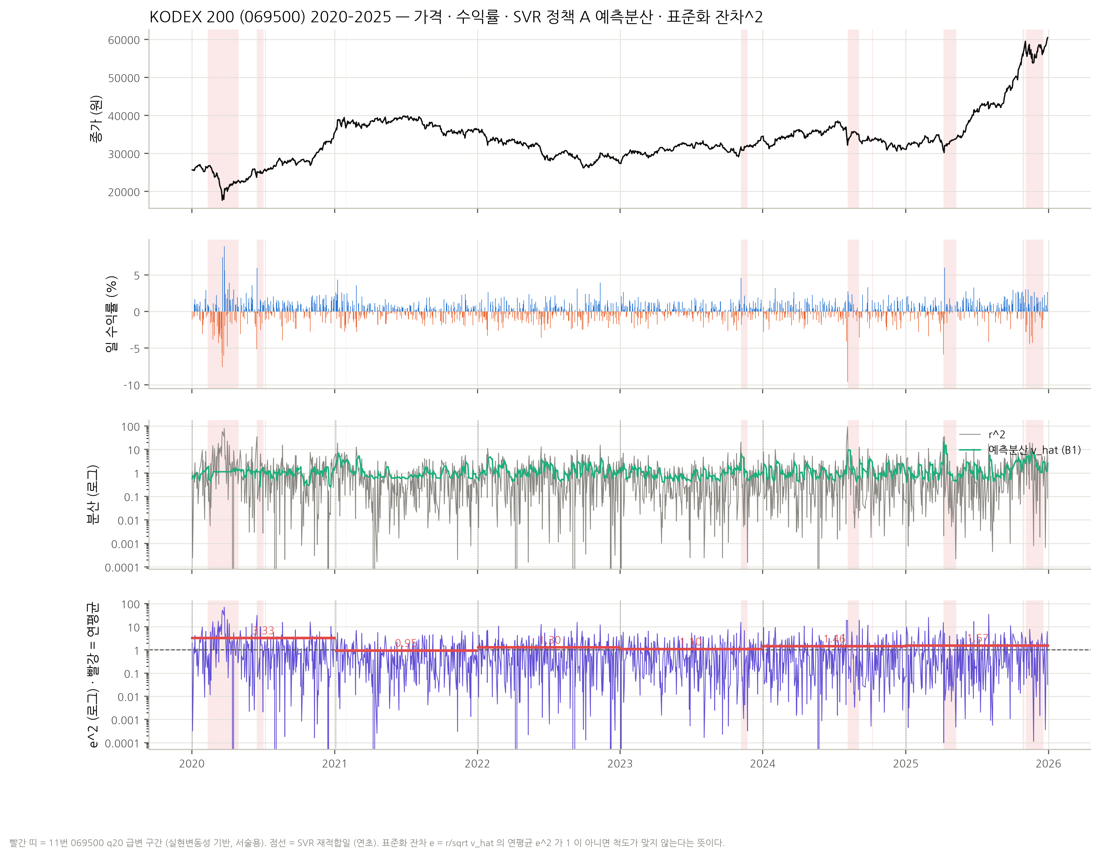

{"mean_e2_by_year": {"2020": 3.3290528661626047, "2021": 0.9485422083717905, "2022": 1.297231102258549, "2023": 1.0969736204889766, "2024": 1.4624922460154053, "2025": 1.5726678657845856}, "n_events": 11}


In [5]:
display(Image(data=preview(FIGDIR / "F01_관측_타임라인.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP.get("F01_관측_타임라인", {}), ensure_ascii=False, default=str)[:600])  # 캡션 수치 (결과 파일에서 계산)

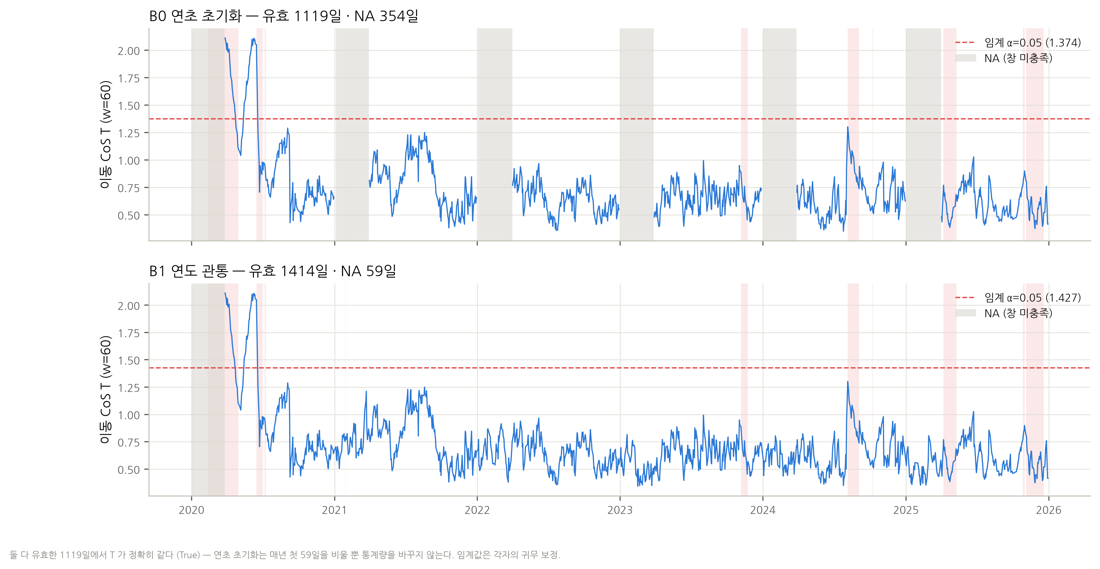

{"both_valid": 1119, "identical": true, "crit_B0": 1.3735305408762053, "crit_B1": 1.4270857079805064, "na_B0": 354, "na_B1": 59}


In [6]:
display(Image(data=preview(FIGDIR / "F02_B0_B1_연초초기화.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP.get("F02_B0_B1_연초초기화", {}), ensure_ascii=False, default=str)[:600])  # 캡션 수치 (결과 파일에서 계산)

## 2. E1 시간 분할 · E2 창 길이

**해석 — E1 시간 분할 · E2 창.**
- E1 의 모든 초기화 일정은 경보 43–45일 (전부 2020) 로 거의 같다. 이동 CoS 의 초기화는 창 내용을 바꾸지 않으므로 바뀌는 것은 **커버리지와 연초 공백**뿐이다. 반년 분할은 유효일이 765일로 반 가까이 줄어든다.
- 합성에서 연초 초기화(B0)는 **연말 변화(S11)** 검출을 오히려 낮춘다 (α=0.20 에서 0.070 → 0.015, 대응 95% 구간 음수 → `DETECTION_POWER_LOSS`). 변화 직후 창이 비어 버리기 때문이다.
- 창이 짧을수록(w20·w30) 같은 α 에서 지속형 변화 검출이 줄고 (대응 손실), w252 는 연말 변화에서만 이득이 있다.
- **X-D7 긴 창 이월**: w252 의 2021 경보 159일 = 2021-01~04 의 COVID 이월 63일 + 2021-06~11 의 '2020 하반기 고잔차 → 2021 저잔차' 분산 감소 96일. 긴 창 CoS 는 '지금' 이 아니라 '최근 w 일 안 어딘가' 의 변화를 말하는 **기억 채널**이다.

In [7]:
# E1·E2: 부모 B1 대비 하나만 바꾼 결과
display(T['experiment_summary.csv'][T['experiment_summary.csv'].family.isin(['E1_time_split','E2_window'])][['experiment_id','changed_variable','value_after','valid_days','T_max','crit_a05','alarm_days_a05','alarm_days_a05_2020','alarm_days_a05_2021_2025','event_alarm_days_a20','event_mean_pctile']])  # 표 출력

,experiment_id,changed_variable,value_after,valid_days,T_max,crit_a05,alarm_days_a05,alarm_days_a05_2020,alarm_days_a05_2021_2025,event_alarm_days_a20,event_mean_pctile
2,E1_half_year,reset,half_year,765.0,2.111091,1.349766,45.0,45.0,0.0,27.0,0.528422
3,E1_two_year,reset,two_year,1296.0,2.111091,1.411497,44.0,44.0,0.0,29.0,0.596750
4,E1_three_year,reset,three_year,1355.0,2.111091,1.420583,43.0,43.0,0.0,29.0,0.594223
5,E1_every_252,reset,every_252,1119.0,2.111091,1.389054,44.0,44.0,0.0,29.0,0.645360
6,E1_every_504,reset,every_504,1296.0,2.111091,1.418896,43.0,43.0,0.0,29.0,0.599134
7,E1_annual_shift21,reset,annual_shift21,1119.0,2.111091,1.392973,44.0,44.0,0.0,29.0,0.640065
8,E1_annual_shift63,reset,annual_shift63,1119.0,2.111091,1.401082,44.0,44.0,0.0,29.0,0.663824
9,E1_annual_shift126,reset,annual_shift126,1119.0,2.111091,1.406904,44.0,44.0,0.0,26.0,0.557476
10,E2_w20,w,20,1454.0,1.802659,1.512620,10.0,10.0,0.0,12.0,0.638451
11,E2_w30,w,30,1444.0,1.959341,1.475732,20.0,20.0,0.0,24.0,0.620173


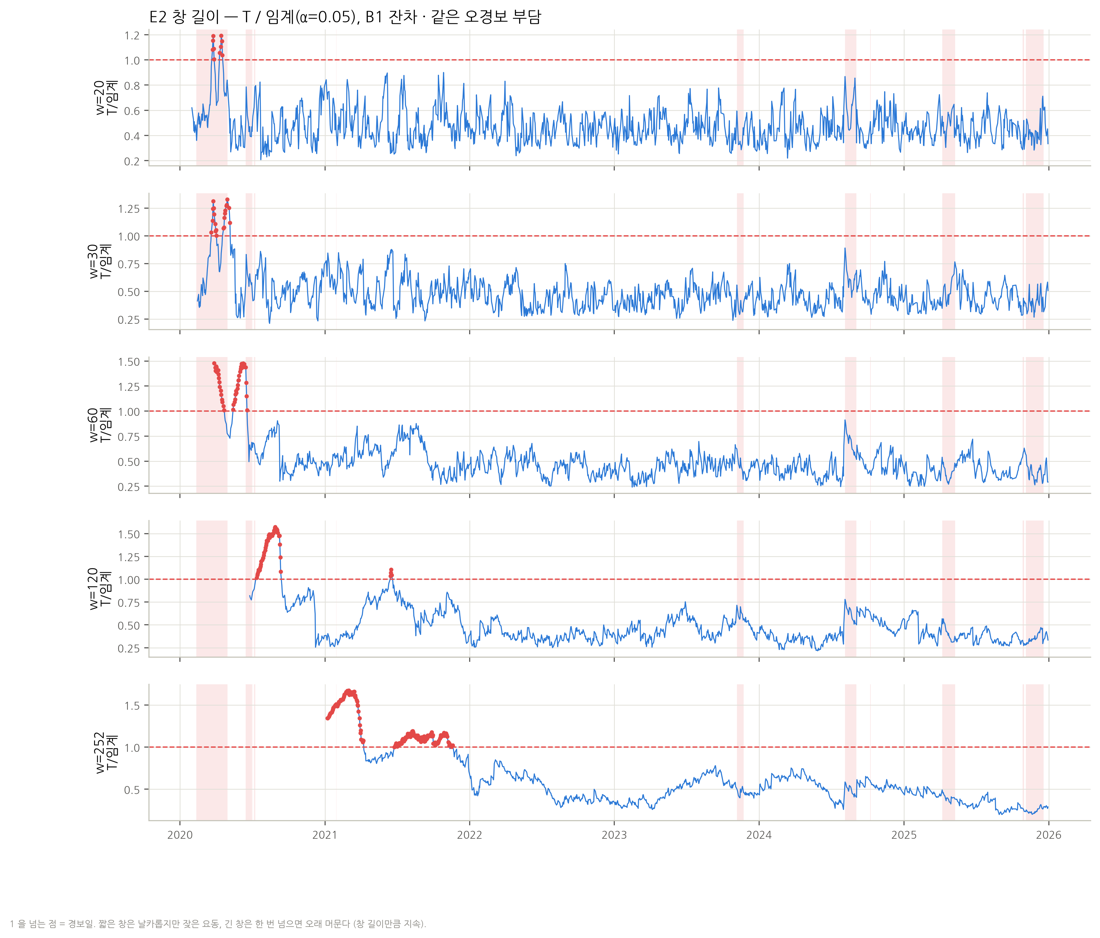

{"20": {"alarm_days_a05": 10, "crit": 1.512620309629551}, "30": {"alarm_days_a05": 20, "crit": 1.4757324374047174}, "60": {"alarm_days_a05": 43, "crit": 1.4270857079805064}, "120": {"alarm_days_a05": 48, "crit": 1.4658981796725705}, "252": {"alarm_days_a05": 159, "crit": 1.5165916613690682}}


In [8]:
display(Image(data=preview(FIGDIR / "F03_창길이_비교.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP.get("F03_창길이_비교", {}), ensure_ascii=False, default=str)[:600])  # 캡션 수치 (결과 파일에서 계산)

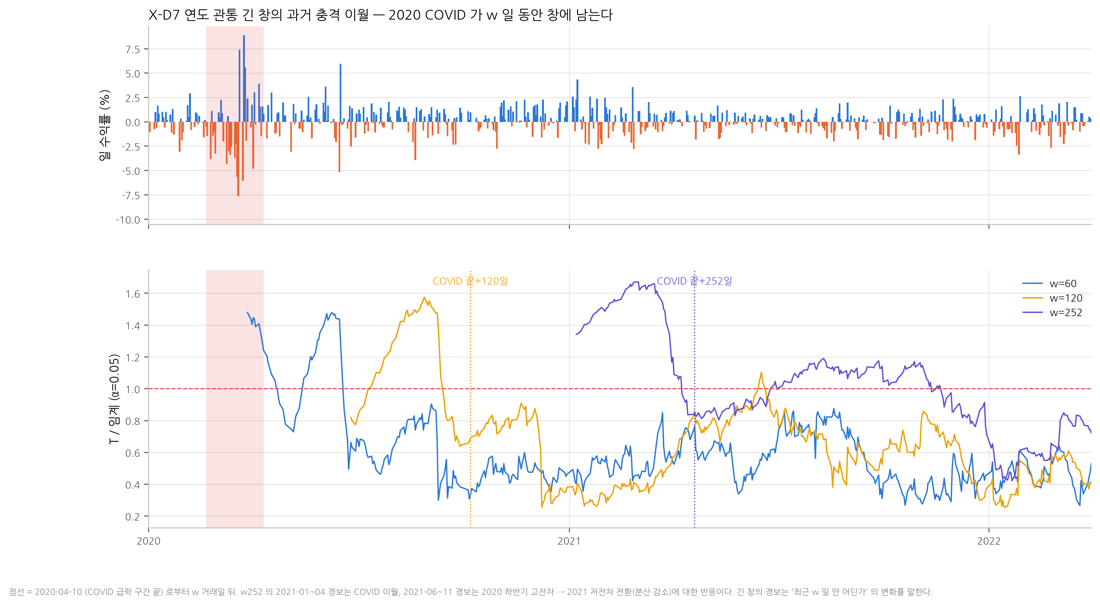

{"60": {"last_alarm": "2020-06-18", "alarm_days": 43}, "120": {"last_alarm": "2021-06-18", "alarm_days": 48}, "252": {"last_alarm": "2021-11-19", "alarm_days": 159}}


In [9]:
display(Image(data=preview(FIGDIR / "F12_긴창_과거충격_이월.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP.get("F12_긴창_과거충격_이월", {}), ensure_ascii=False, default=str)[:600])  # 캡션 수치 (결과 파일에서 계산)

## 3. E3 CUSUM 공식 — 이동 CoS · Page · 사후 · 원수익률

**해석 — E3 통계량 공식.**
- Page 상방(λ=2) 은 귀무에서도 임계 h≈57 이 필요하다. 정책 A 잔차의 척도가 1 보다 크면 상방 증분이 양수로 기울어 상태가 계속 쌓이기 때문이다. 관측 자유 상태는 2020 에 120 까지 올라 2025 까지 내려오지 않는다 (F04) → **피처로도 비정상(추세) 신호**라 AE 입력에서 뺀다.
- 원수익률 CoS(SVR 없이) 는 군집 귀무에서 임계가 2.22 로 높아 관측 경보 0일. 군집 자체가 큰 CoS 값을 만든다.
- **X1 자기정규화 Page** (e/√m̂, m̂=과거 [t−252, t−61] 평균 e²): 합성 하루 극단(S08) 검출 0.325 → 0.640 (대응 +0.315, 구간 0.23–0.40), 분산 ×3 에서도 0.095 로 크기를 넘는다 (Wilson 하한 0.062). 사후 확장이므로 `EXPLORATORY_EXTENSION` — 채택은 독립 검증 뒤.

In [10]:
# E3 + X1 자기정규화 Page
display(T['experiment_summary.csv'][T['experiment_summary.csv'].family.isin(['E3_statistic','EXPLORATORY_EXTENSION'])][['experiment_id','changed_variable','value_after','valid_days','T_max','crit_a05','alarm_days_a05','alarm_days_a05_2020','alarm_days_a05_2021_2025','event_alarm_days_a20','event_mean_pctile']])  # 표 출력

,experiment_id,changed_variable,value_after,valid_days,T_max,crit_a05,alarm_days_a05,alarm_days_a05_2020,alarm_days_a05_2021_2025,event_alarm_days_a20,event_mean_pctile
14,E3_page_up,detector,page_up,1473.0,122.560769,56.991184,2.0,2.0,0.0,3.0,0.397557
15,E3_page_down,detector,page_down,1473.0,4.688733,3.802755,1.0,0.0,1.0,0.0,0.438996
16,E3_page_two,detector,page_two,1473.0,122.560769,71.237194,1.0,1.0,0.0,2.0,0.397557
17,E3_posthoc_full,detector,posthoc_full,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
18,E3_raw_rolling_cos,detector,raw_rolling_cos,1414.0,2.140118,2.223107,0.0,0.0,0.0,9.0,0.688325
461,X1_page_up_sn,detector,page_up_sn,1293.0,6.506745,14.079045,0.0,0.0,0.0,0.0,0.638914
462,X1_page_down_sn,detector,page_down_sn,1293.0,34.720808,8.365179,4.0,1.0,3.0,0.0,0.393707
463,X1_page_two_sn,detector,page_two_sn,1293.0,34.720808,18.401454,3.0,1.0,2.0,0.0,0.472728


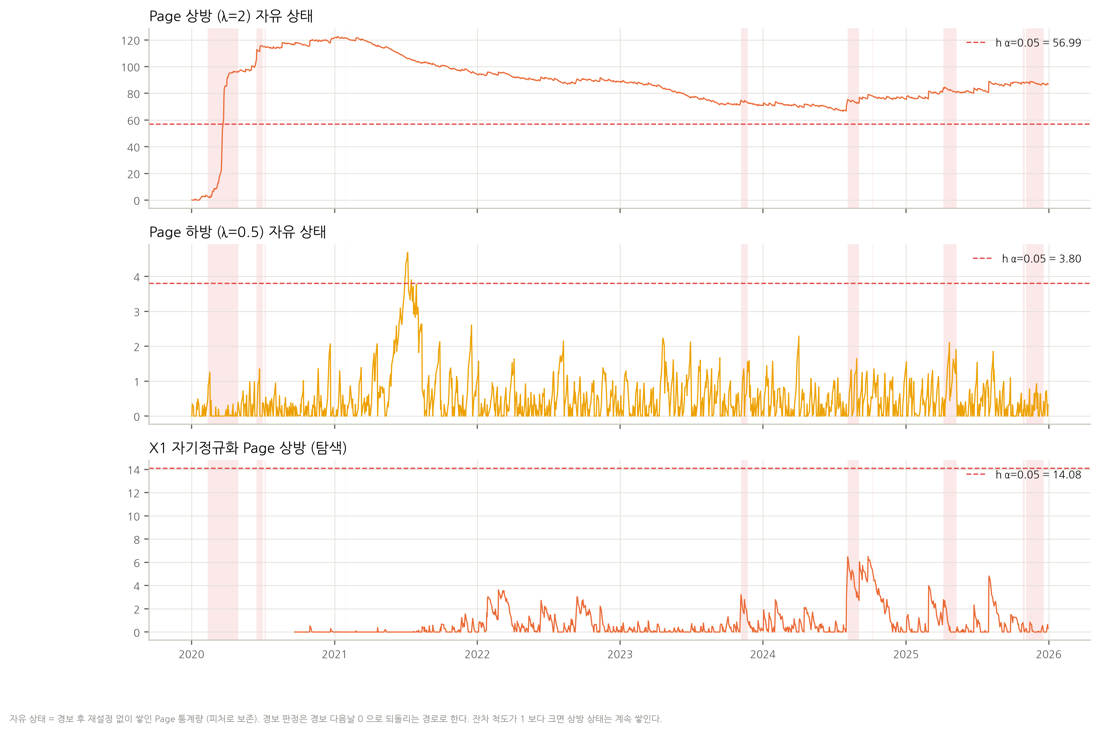

{"E3_page_up": {"max": 122.56076949931632, "h": 56.99118447823773}, "E3_page_down": {"max": 4.688732963844652, "h": 3.802755207384804}, "X1_page_up_sn": {"max": 6.506745056834845, "h": 14.079045181118989}}


In [11]:
display(Image(data=preview(FIGDIR / "F04_Page_CUSUM.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP.get("F04_Page_CUSUM", {}), ensure_ascii=False, default=str)[:600])  # 캡션 수치 (결과 파일에서 계산)

## 4. E4 변화점 네 계열 · E5 변화점 초기화와 위약

**해석 — E4 변화점 · E5 초기화와 위약.**
- q=0.99·불응기 20 규칙의 트리거는 **2020 과 2024 에 몰린다** (M·P·V60 은 2020 이 100%). 17개 계열 중 다수가 사건(11번 q20 구간) ±5일 안 비율이 기저율 0.11 보다 높지만 사건이 7개뿐이라 서술로만 쓴다.
- 관측 위약 비교 (사건일 평균 백분위): 실제 변화점 초기화가 무작위 위약 95% 분위를 넘은 규칙은 이동 CoS 9/102, Page 양방향 8/102 — **다중성 우연 수준**이고, 75%(CoS)·64%(Page) 는 오히려 위약 평균보다 낮다. 관측 `RESET_TRIGGER_GAIN` 없음.
- 합성: 이동 CoS 의 변화점 초기화는 지속형 변화 검출을 **낮춘다** (S02·S03·S05·S09·S10 에서 대응 손실) — 변화 직후 창을 비워 버린다. Page 는 반대로 초기화가 누적된 척도 편향을 지워 하루 극단(S08) 검출이 오른다 (Page 상방 +0.145). 같은 횟수 무작위 위약보다 높은 경우(`RESET_TRIGGER_GAIN`)는 Page 상방 S08 (+0.065) 과 Page 양방향 S02·S05·S10 (+0.02) 뿐이다.

In [12]:
# E4 규칙별 트리거 수·연도 집중·사건 근접 (q=0.99, 불응기 20)
display(T['change_point_summary.csv'].query('q==0.99 and gap==20'))  # 표 출력

,rule,family,q,gap,n_triggers,n_2020,n_2021,n_2022,n_2023,n_2024,n_2025,max_year_share,herfindahl_year,share_in_event,share_near_event_pm5,event_base_rate,events_with_trigger_20d_before,median_lead_days,direction_up_share
5,K120,K,0.99,20,5,0,0,0,0,4,1,0.800000,0.680000,0.200000,0.200000,0.113374,1,10.0,0.800000
11,K60,K,0.99,20,8,4,0,0,0,4,0,0.500000,0.500000,0.250000,0.250000,0.113374,0,NaN,0.500000
17,M10_60,M,0.99,20,1,1,0,0,0,0,0,1.000000,1.000000,1.000000,1.000000,0.113374,0,NaN,0.000000
23,M20_60,M,0.99,20,2,2,0,0,0,0,0,1.000000,1.000000,0.500000,0.500000,0.113374,0,NaN,0.500000
29,M5_20,M,0.99,20,3,2,0,0,0,1,0,0.666667,0.555556,0.666667,0.666667,0.113374,1,6.0,0.333333
35,P10,P,0.99,20,4,2,0,0,0,1,1,0.500000,0.375000,0.750000,0.750000,0.113374,1,6.0,0.250000
41,P20,P,0.99,20,1,1,0,0,0,0,0,1.000000,1.000000,1.000000,1.000000,0.113374,0,NaN,0.000000
47,P5,P,0.99,20,5,2,0,0,1,1,1,0.400000,0.280000,0.800000,0.800000,0.113374,1,7.0,0.600000
53,V20_down,V,0.99,20,3,1,0,0,0,1,1,0.333333,0.333333,0.333333,0.666667,0.113374,1,10.0,0.000000
59,V20_two,V,0.99,20,5,3,0,0,0,1,1,0.600000,0.440000,0.400000,0.600000,0.113374,1,6.0,0.600000


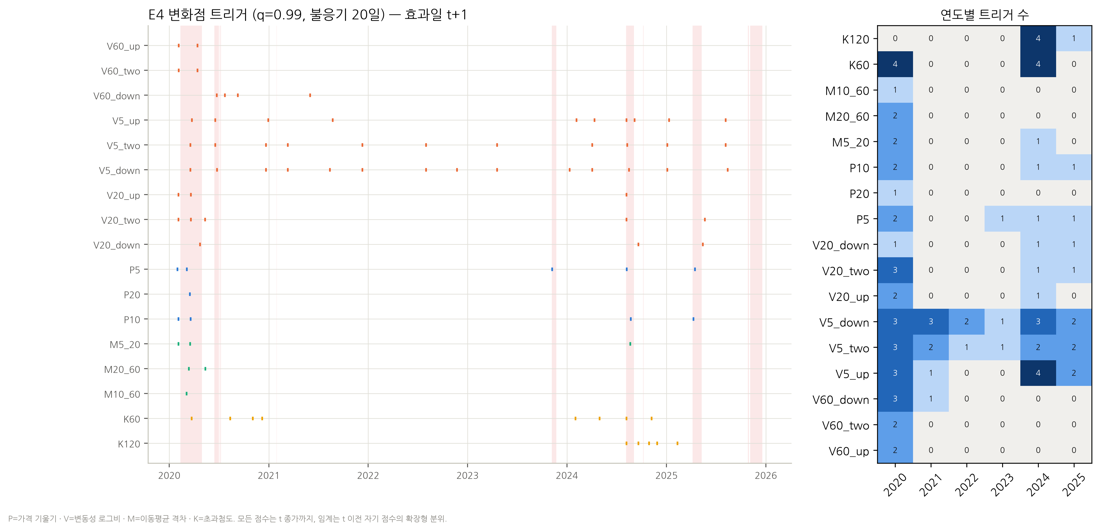

{"n_rules": 17, "total_triggers": 83, "max_year_share_median": 0.6666666666666666}


In [13]:
display(Image(data=preview(FIGDIR / "F05_변화점_트리거.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP.get("F05_변화점_트리거", {}), ensure_ascii=False, default=str)[:600])  # 캡션 수치 (결과 파일에서 계산)

In [14]:
# E5 실제 변화점 초기화 vs 무작위·이동 위약 (사건일 백분위)
display(T['placebo_comparison.csv'].query('metric=="event_mean_pctile" and q==0.99 and gap==20'))  # 표 출력

,rule,q,gap,detector,n_resets,metric,real,calendar,random_mean,random_q95,random_p_ge,shift_mean,shift_q95,shift_p_ge
42,K120,0.99,20,rolling_cos,5,event_mean_pctile,0.619838,0.580725,0.604987,0.701617,0.338308,0.597440,0.678110,0.238806
46,K120,0.99,20,page_two,5,event_mean_pctile,0.339157,0.778652,0.708869,0.827576,1.000000,0.517698,0.827415,0.835821
90,K60,0.99,20,rolling_cos,8,event_mean_pctile,0.455304,0.611933,0.604311,0.738324,0.970149,0.604298,0.813061,0.980100
94,K60,0.99,20,page_two,8,event_mean_pctile,0.793728,0.800670,0.723473,0.828871,0.208955,0.692240,0.837619,0.303483
138,M10_60,0.99,20,rolling_cos,1,event_mean_pctile,0.539526,0.594735,0.603141,0.661049,0.975124,0.598242,0.644640,0.955224
142,M10_60,0.99,20,page_two,1,event_mean_pctile,0.397411,0.491634,0.528338,0.801837,0.691542,0.519858,0.811147,0.651741
186,M20_60,0.99,20,rolling_cos,2,event_mean_pctile,0.488633,0.597303,0.608708,0.697401,1.000000,0.604389,0.670404,0.990050
190,M20_60,0.99,20,page_two,2,event_mean_pctile,0.732342,0.618293,0.583891,0.800450,0.238806,0.527647,0.817973,0.194030
234,M5_20,0.99,20,rolling_cos,3,event_mean_pctile,0.521190,0.562226,0.605583,0.695907,0.965174,0.597654,0.687653,0.930348
238,M5_20,0.99,20,page_two,3,event_mean_pctile,0.345185,0.692430,0.648753,0.819988,0.965174,0.615192,0.805177,0.945274


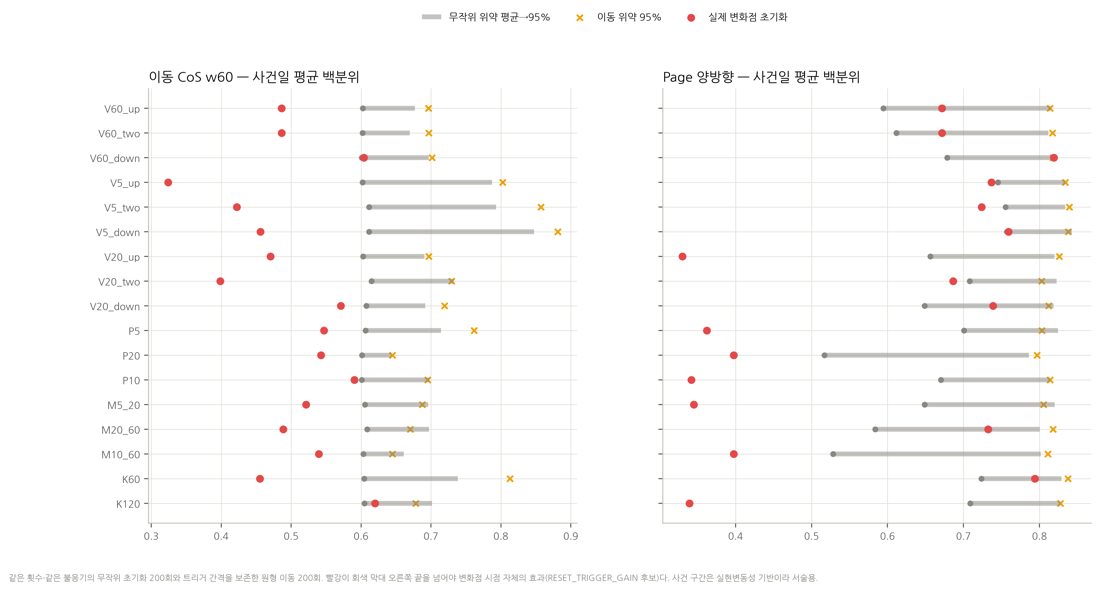

{"rolling_cos": {"real_gt_random_q95": 0, "n": 17}, "page_two": {"real_gt_random_q95": 0, "n": 17}}


In [15]:
display(Image(data=preview(FIGDIR / "F06_변화점초기화_위약.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP.get("F06_변화점초기화_위약", {}), ensure_ascii=False, default=str)[:600])  # 캡션 수치 (결과 파일에서 계산)

## 5. E6–E10 SVR 학습기간 · 재학습 빈도 · 변화점 반응 · 유예 · 적응형

**해석 — E6–E10 SVR 정책.**
- QLIKE (낮을수록 좋음): 전체 2020–2025 에서는 변화점 재학습(1.547)·적응형(1.544)·21일 재학습(1.580) 이 B1(1.716) 보다 좋다. 그러나 **2021–2025 만 보면 모두 1.393–1.402 로 같다** — 이득은 전부 2020 (2019 로만 학습한 모형이 COVID 를 만난 해) 에서 나온다. 짧은 학습창(직전 252일)은 2021–2025 에서도 1.525 로 나쁘다.
- 관측 경보: 변화점 재학습만 하면 B1 43 → 31일 (2020 충격을 더 빨리 흡수).
- **X-D6 재학습 경계 단절**: 유예 20·60일 정책만 2021-01~02 에 경보 27·26일. 2020 하반기 재적합이 ε=1.0 을 골라 분산을 과대추정 → e² 평균 0.29 → 2021-01-04 새 적합에서 1.35 (log2 +2.2). 한 창에 두 모형의 잔차가 섞인 **구현 기원 경보**다 (`FALSE_ALARM_INCREASE`). 재적합일마다 창을 끊으면 27 → 0 이지만 커버리지를 잃는다 (21일 재학습은 창보다 짧아 유효일 0).
- 합성: 재학습 정책들은 대부분 `LOW_POWER_INCONCLUSIVE`. 의미 있는 이득은 Page 양방향의 하루 극단(21일 재학습 +0.085) 정도다.

In [16]:
# E6–E10 관측 경보 (부모 B1 또는 E3 Page)
display(T['experiment_summary.csv'][T['experiment_summary.csv'].family.str.match('E(6|7|8|9|10)_')][['experiment_id','changed_variable','value_after','valid_days','T_max','crit_a05','alarm_days_a05','alarm_days_a05_2020','alarm_days_a05_2021_2025','event_alarm_days_a20','event_mean_pctile']])  # 표 출력

,experiment_id,changed_variable,value_after,valid_days,T_max,crit_a05,alarm_days_a05,alarm_days_a05_2020,alarm_days_a05_2021_2025,event_alarm_days_a20,event_mean_pctile
430,E6_win252,svr,win252,1414.0,2.111091,1.648555,33.0,33.0,0.0,23.0,0.627515
431,E6_win252_page_two,svr,win252,1473.0,157.299665,81.441596,1.0,1.0,0.0,3.0,0.511232
432,E6_win504,svr,win504,1414.0,2.111091,1.489741,40.0,40.0,0.0,27.0,0.596899
433,E6_win504_page_two,svr,win504,1473.0,122.560769,71.237194,1.0,1.0,0.0,2.0,0.512322
434,E6_win756,svr,win756,1414.0,2.111091,1.446131,41.0,41.0,0.0,29.0,0.589531
435,E6_win756_page_two,svr,win756,1473.0,122.560769,70.185413,1.0,1.0,0.0,2.0,0.473072
436,E7_refit63,svr,refit63,1414.0,2.148582,1.406351,43.0,43.0,0.0,26.0,0.604873
437,E7_refit63_page_two,svr,refit63,1473.0,96.613848,64.192932,1.0,1.0,0.0,2.0,0.455702
438,E7_refit21,svr,refit21,1414.0,2.059440,1.390011,39.0,39.0,0.0,22.0,0.583926
439,E7_refit21_page_two,svr,refit21,1473.0,48.652626,62.311374,1.0,1.0,0.0,1.0,0.693223


In [17]:
# 정책별 QLIKE · 평균 e^2 · 재적합 단절비
display(T['svr_training_summary.csv'].query('year=="all"'))  # 표 출력

,pipeline,year,n_eligible,n_refits,mean_e2,qlike,mse_var,nonpos_var_days,refit_jump_median,ordinary_jump_median,refit_jump_ratio
0,B1,all,1473,6,1.619929,1.715990,25.253430,0,0.246052,0.150701,1.632717
7,win252,all,1472,6,1.804274,1.825744,24.989888,1,0.163945,0.212195,0.772618
14,win504,all,1473,6,1.689332,1.756146,24.939547,0,0.195384,0.155385,1.257416
21,win756,all,1473,6,1.661727,1.751139,24.904733,0,0.277509,0.156862,1.769130
28,refit63,all,1473,24,1.549939,1.690792,25.544790,0,0.245669,0.160077,1.534690
35,refit21,all,1473,71,1.385489,1.579612,25.515118,0,0.234652,0.154751,1.516315
42,refitV20_g0,all,1473,11,1.379444,1.547426,23.921603,0,0.239841,0.160221,1.496938
49,refitV20_g20,all,1473,11,1.301261,1.610540,26.686149,0,0.252136,0.127114,1.983536
56,refitV20_g60,all,1473,11,1.470572,1.729617,26.792881,0,0.281982,0.128220,2.199203
63,adaptiveV20,all,1472,15,1.386319,1.544068,23.487444,1,0.163388,0.165738,0.985818


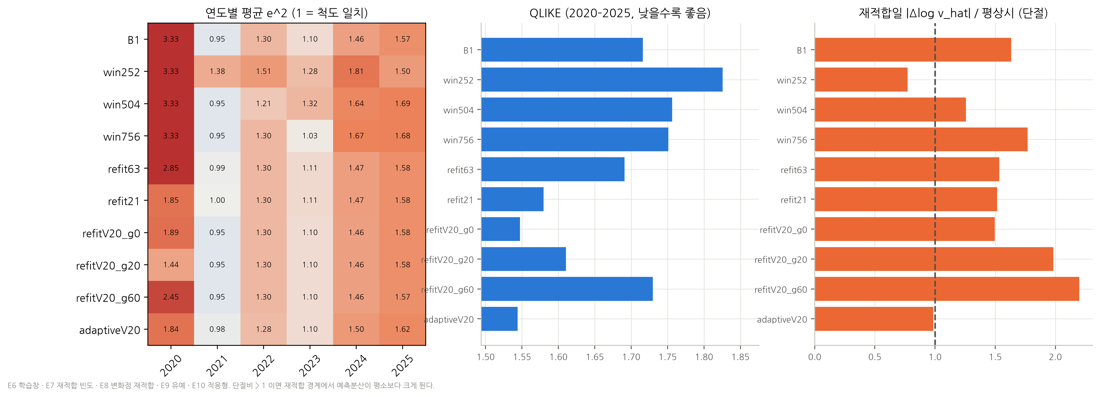

{"qlike": {"B1": 1.716, "win252": 1.8257, "win504": 1.7561, "win756": 1.7511, "refit63": 1.6908, "refit21": 1.5796, "refitV20_g0": 1.5474, "refitV20_g20": 1.6105, "refitV20_g60": 1.7296, "adaptiveV20": 1.5441}, "jump_ratio": {"B1": 1.633, "win252": 0.773, "win504": 1.257, "win756": 1.769, "refit63": 1.535, "refit21": 1.516, "refitV20_g0": 1.497, "refitV20_g20": 1.984, "refitV20_g60": 2.199, "adaptiveV20": 0.986}}


In [18]:
display(Image(data=preview(FIGDIR / "F07_SVR_정책.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP.get("F07_SVR_정책", {}), ensure_ascii=False, default=str)[:600])  # 캡션 수치 (결과 파일에서 계산)

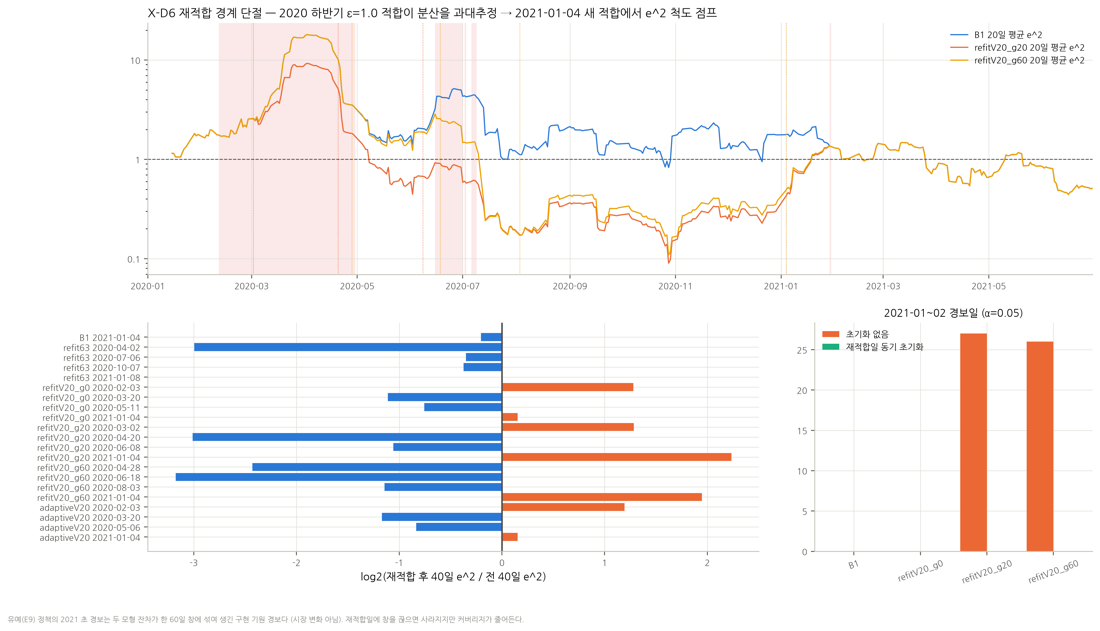

{"g20_log2_ratio_2021": 2.233462931, "g20_pre_mean_e2": 0.2864540498, "alarms_JanFeb": {"no_reset": {"B1": 0, "refitV20_g0": 0, "refitV20_g20": 27, "refitV20_g60": 26}, "refit_synced_reset": {"B1": 0, "refitV20_g0": 0, "refitV20_g20": 0, "refitV20_g60": 0}}}


In [19]:
display(Image(data=preview(FIGDIR / "F11_재적합경계_단절.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP.get("F11_재적합경계_단절", {}), ensure_ascii=False, default=str)[:600])  # 캡션 수치 (결과 파일에서 계산)

## 6. E11 임계값·귀무 보정 · 귀무 적합성 · 크기 감사

**해석 — E11 보정 · 귀무 적합성 · 크기 감사.**
- 같은 B1·w60 통계량에 보정만 바꾼 홀드아웃 오경보율(α=0.05 목표): 점근 1.3397 → 0.10, 정규 MC → 0.012, 사전 iid 부트스트랩 → 0.016, 사전 블록 부트스트랩 → 0.195, GARCH-t 전체 파이프라인(N1) → 0.060. **귀무 선택만으로 오경보율이 0.01–0.20 으로 갈린다.**
- 관측 잔차는 N1 귀무의 99% 범위를 2020 (LB·ARCH) 과 2021 (첨도) 에서 벗어난다 → 모든 SVR 파이프라인 `NULL_MODEL_INVALID`. 관측 p 값은 확증용이 아니다.
- 크기 감사: Wilson 기준 549/1068 행만 통과. 그러나 블록 ICC 중앙 0.12, 보정·홀드아웃 역할을 바꾸면 방향이 뒤집힌다 (w60: 6.0% → 4.2%). **체계 편향이 아니라 두 귀무 표본 사이 공통 요동**이며, 모든 설정이 같은 경로를 공유해 한꺼번에 나타난다 (X-D5). 오경보율 오차 ±1–1.5%p 를 전제로 읽는다.
- N0 (2019 단독 GARCH-t) 는 α=0 으로 퇴화해 iid t 귀무였다. 그 결과는 `results_n0_iid_t_2019/` 에 실패 기록으로 남겼다.

In [20]:
# 관측 잔차가 N1 귀무 99% 범위 밖인 (파이프라인, 연도, 통계)
display(T['null_validity.csv'].query('outside'))  # 표 출력

,pipeline,year,stat,observed,null_q005,null_q995,null_median,outside
2,B1,2020,lb_e2_q10,252.530406,1.046018,70.537924,10.131655,True
3,B1,2020,archlm5,101.656960,0.448506,33.095392,6.106465,True
5,B1,2021,excess_kurtosis,-0.152451,-0.011245,17.682529,1.643383,True
26,win252,2020,lb_e2_q10,252.530406,1.046018,70.537924,10.131655,True
27,win252,2020,archlm5,101.656960,0.448506,33.095392,6.106465,True
50,win504,2020,lb_e2_q10,252.530406,1.046018,70.537924,10.131655,True
51,win504,2020,archlm5,101.656960,0.448506,33.095392,6.106465,True
53,win504,2021,excess_kurtosis,-0.152451,-0.011245,17.682529,1.643383,True
74,win756,2020,lb_e2_q10,252.530406,1.046018,70.537924,10.131655,True
75,win756,2020,archlm5,101.656960,0.448506,33.095392,6.106465,True


In [21]:
# 홀드아웃 크기 실패 분해 (통계량·창·SVR·초기화 계열)
display(T['size_fail_decomposition.csv'].query('n_fail_wilson>0').head(40))  # 표 출력

,calibration,detector,w,svr,reset_family,alpha,n,n_fail_wilson,n_fail_cluster,mean_holdout,max_holdout,mean_icc,observed_null_invalid
0,asymptotic,rolling_cos,60.0,B1,none,0.05,1,1,1,0.101600,0.1016,0.128462,True
1,asymptotic,rolling_cos,60.0,B1,none,0.20,1,1,1,0.101600,0.1016,0.128462,True
2,block_bootstrap_presample,rolling_cos,60.0,B1,none,0.05,1,1,1,0.195200,0.1952,0.123359,True
3,block_bootstrap_presample,rolling_cos,60.0,B1,none,0.20,1,1,1,0.411200,0.4112,0.067858,True
4,garch_t_N1,page_down,NaN,B1,calendar,0.05,1,1,1,0.067200,0.0672,0.215698,True
6,garch_t_N1,page_down,NaN,B1,cp_K,0.05,12,12,12,0.066200,0.0676,0.236017,True
8,garch_t_N1,page_down,NaN,B1,cp_M,0.05,18,18,18,0.066711,0.0672,0.236952,True
10,garch_t_N1,page_down,NaN,B1,cp_P,0.05,18,18,18,0.066733,0.0672,0.239706,True
12,garch_t_N1,page_down,NaN,B1,cp_V,0.05,54,53,48,0.066444,0.0712,0.223283,True
13,garch_t_N1,page_down,NaN,B1,cp_V,0.20,54,9,4,0.213733,0.2288,0.174840,True


In [22]:
# X-D5 보정 표본오차 · 역할 교환 검사
display(pd.read_csv(RES / 'size_calibration_uncertainty.csv'))  # 표 출력

,detector,svr,alpha,crit_cal,holdout_rate,calib_uncert_q025,calib_uncert_q975,consistent_with_calib_noise,swap_crit_from_hold,swap_rate_on_cal
0,rolling_cos_w20,B1,0.05,1.512620,0.0580,0.05320,0.06463,False,1.522119,0.0442
1,rolling_cos_w20,B1,0.20,1.384159,0.2156,0.20200,0.22240,False,1.392498,0.1868
2,rolling_cos_w60,B1,0.05,1.427086,0.0600,0.05080,0.07120,False,1.457940,0.0422
3,rolling_cos_w60,B1,0.20,1.224087,0.2060,0.19600,0.21520,True,1.229104,0.1930
4,rolling_cos_w252,B1,0.05,1.516592,0.0640,0.05320,0.07221,False,1.644419,0.0386
5,rolling_cos_w252,B1,0.20,1.159622,0.2248,0.21257,0.23760,False,1.186687,0.1762


## 7. 합성 검정 — 같은 오경보 부담(α)에서 13 시나리오 검출률·지연

**해석 — 합성 검출 (관측과 별개 판정).**
- **지속형 분산 변화 (×1.5·×2·×3·점진·장기·반복·연말) 는 모든 탐지기에서 크기 수준**이다 (α=0.05 검출 최대 0.095) → `LOW_POWER_INCONCLUSIVE`. 정책 A 는 직전 5일 제곱수익률을 입력으로 새 분산을 며칠 만에 흡수하고, 군집 귀무(지속성 0.945) 의 정상 요동이 이미 ×3 수준이라 연 5% 오경보 부담에서는 이 크기의 변화가 구별되지 않는다.
- 크기와 구별되는 검출력 (Wilson 하한 > α, 그림 F08 의 *): 하루 극단 S08 — Page 상방 0.325, 양방향 0.145, X1 자기정규화 상방 0.640 · 분산 감소 S12 — Page 하방 0.085 · 분산 ×3 S03 — X1 상방 0.095.
- 검출 지연 곡선 (F15): 하루 극단은 대부분 **당일** 잡히고 이후 거의 늘지 않는다. 지속형 변화는 60일 내내 α 선 근처.
- **X9 예측분산 수준 탐지기** (잔차 대신 log v̂ 의 과거 대비 수준): ×3 에서 0.095/0.270 (α 0.05/0.20) — CoS w60 0.065/0.150 보다 약간 높지만 대응 구간을 내지 않았고 승격하지 않았다.

In [23]:
# B1 잔차·원수익률 탐지기의 시나리오별 검출률 (α=0.05)
display(T['synthetic_size_power.csv'].query('alpha==0.05 and reset=="none" and svr in ["B1","NA"]').pivot_table(index=['detector','w'], columns='scenario', values='detection_rate'))  # 표 출력

scenario             S01_var_x1.5  S02_var_x2  S03_var_x3  S04_short_shock  S05_long_persistent  S06_gradual  S07_mean_shift  S08_one_day_extreme  S09_up_then_down  S10_repeated  S11_year_boundary  S12_var_x0.5
detector        w                                                                                                                                                                                                 
page_down       NA          0.005       0.005       0.000            0.015                0.005        0.005           0.005                0.015             0.000         0.005              0.005         0.085
page_down_sn    NA          0.020       0.015       0.010            0.025                0.015        0.015           0.010                0.020             0.015         0.015              0.010         0.070
page_two        NA          0.015       0.015       0.030            0.015                0.015        0.015           0.010                0.145             0.010         0.015              0.010         0.035
page_two_sn     NA          0.020       0.025       0.060            0.015                0.025        0.015           0.015                0.455             0.055         0.025              0.035         0.030
page_up         NA          0.025       0.045       0.080            0.015                0.045        0.040           0.020                0.325             0.060         0.040              0.035         0.010
page_up_sn      NA          0.025       0.045       0.095            0.035                0.045        0.045           0.010                0.640             0.090         0.045              0.060         0.005
raw_rolling_cos 120         0.015       0.020       0.055            0.010                0.020        0.015           0.015                0.000             0.045         0.020              0.035         0.025
                20          0.010       0.005       0.010            0.020                0.005        0.010           0.020                0.010             0.010         0.005              0.010         0.015
                60          0.035       0.035       0.030            0.020                0.035        0.050           0.030                0.000             0.030         0.035              0.015         0.035
rolling_cos     120         0.040       0.040       0.065            0.035                0.040        0.045           0.035                0.020             0.065         0.040              0.025         0.045
                20          0.005       0.000       0.000            0.010                0.000        0.000           0.015                0.015             0.010         0.000              0.010         0.010
                252         0.030       0.035       0.050            0.025                0.035        0.035           0.025                0.015             0.040         0.035              0.035         0.040
                30          0.010       0.010       0.035            0.010                0.010        0.010           0.015                0.015             0.045         0.010              0.015         0.010
                60          0.033       0.039       0.061            0.032                0.039        0.036           0.025                0.019             0.062         0.039              0.026         0.057

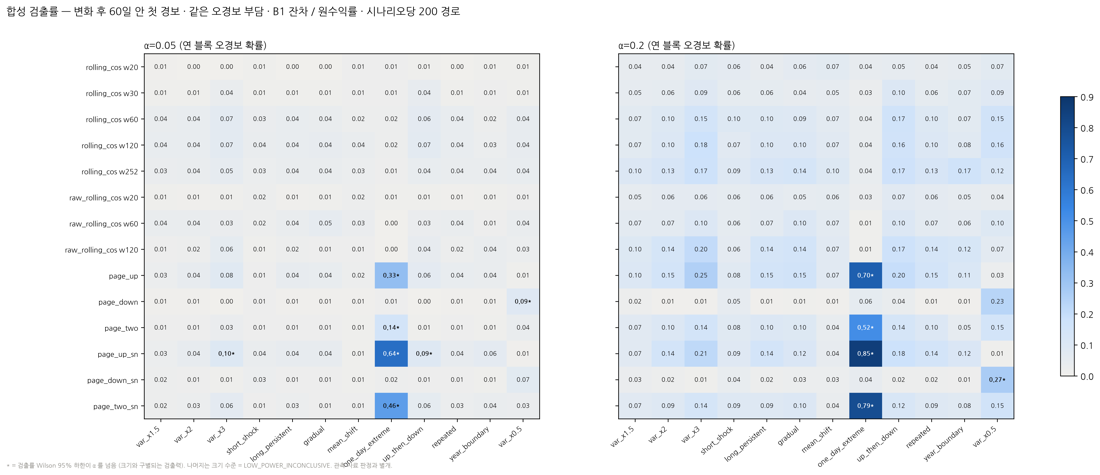

{"0.05": {"n_above_size": 7, "max_rate": 0.64}, "0.2": {"n_above_size": 5, "max_rate": 0.855}}


In [24]:
display(Image(data=preview(FIGDIR / "F08_합성_검출률.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP.get("F08_합성_검출률", {}), ensure_ascii=False, default=str)[:600])  # 캡션 수치 (결과 파일에서 계산)

## 8. 실제 사건 상세 · 사건 유형별 반응

**해석 — 실제 사건 (11번 069500 q20 구간, 서술용).**
- 가장 긴 세 구간 확대 (F10: 2020-02~04 · 2025-04~05 · 2025-11~12): 2020 COVID 구간에서만 잔차 CoS w60 이 임계를 넘는다 (최대 T/임계 1.48). 2025-04 (급락·급반등 두 날) 0.54, 2025-11~12 누적형 0.57 로 임계의 절반 수준이다.
- **X-D8 사건 유형별 반응** (2021–2025, 누적형 4 · 단일 충격형 3): 잔차 기반 탐지기는 단일 충격형에서 자기 분포 백분위가 더 높다 (w120 0.67 vs 0.35, Page 하방 0.65 vs 0.38, X1 상방 0.81 vs 0.55). 원수익률 CoS 는 누적형에서 약간 높다 (0.66 vs 0.60). 합성의 하루 극단 검출(Page) 과 같은 방향이지만, 사건 7개라 일반화하지 않는다.

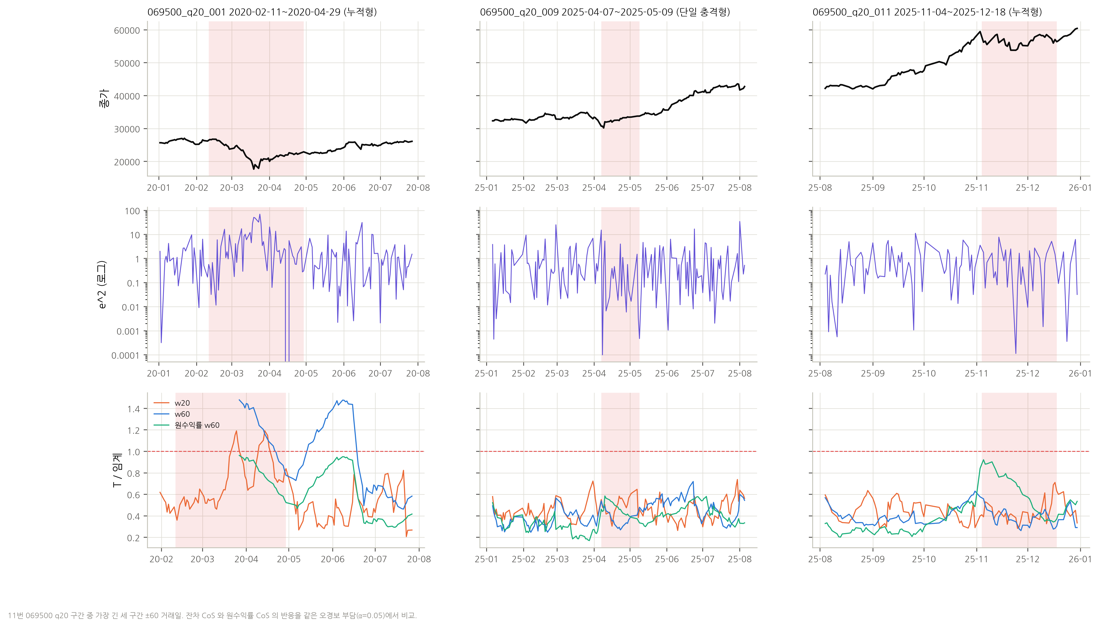

{"069500_q20_001": {"maxT_over_crit_w60": 1.4793019381571315}, "069500_q20_009": {"maxT_over_crit_w60": 0.5391305868958832}, "069500_q20_011": {"maxT_over_crit_w60": 0.5678172932617886}}


In [25]:
display(Image(data=preview(FIGDIR / "F10_사건_확대.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP.get("F10_사건_확대", {}), ensure_ascii=False, default=str)[:600])  # 캡션 수치 (결과 파일에서 계산)

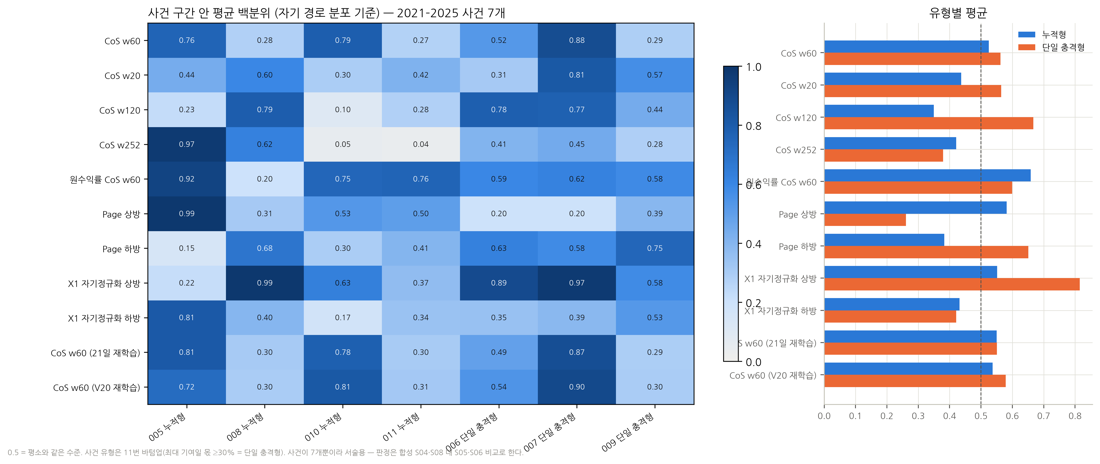

{"type_means": {"누적형": {"CoS w60": 0.525, "CoS w20": 0.437, "CoS w120": 0.349, "CoS w252": 0.421, "원수익률 CoS w60": 0.658, "Page 상방": 0.582, "Page 하방": 0.383, "X1 자기정규화 상방": 0.552, "X1 자기정규화 하방": 0.431, "CoS w60 (21일 재학습)": 0.55, "CoS w60 (V20 재학습)": 0.537}, "단일 충격형": {"CoS w60": 0.562, "CoS w20": 0.564, "CoS w120": 0.667, "CoS w252": 0.379, "원수익률 CoS w60": 0.599, "Page 상방": 0.261, "Page 하방": 0.651, "X1 자기정규화 상방": 0.815, "X1 자기정규화 하방": 0.421, "CoS w60 (21일 재학습)": 0.551, "CoS w60 (V20 재학습)": 0.579}}}


In [26]:
display(Image(data=preview(FIGDIR / "F13_사건유형별_반응.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP.get("F13_사건유형별_반응", {}), ensure_ascii=False, default=str)[:600])  # 캡션 수치 (결과 파일에서 계산)

## 9. Autoencoder 피처 인계 — 중복성 · 추가 정보 · 관측 가능 시점

**해석 — Autoencoder 인계.**
- 모든 후보 피처는 t 종가까지의 정보다 (예측분산은 t−1 종가에 t 를 예측). 미래 RV20 은 평가 전용(`POSTHOC_ONLY`).
- **중복으로 뺄 것**: `cos_w60_B0` (B1 과 유효일 동일) · `e_B1` (수익률과 0.99) · `abs_ret` (e² 와 0.95) · `cos_w60_refit21` (B1 과 0.89).
- **비정상이라 뺄 것**: `page_up_B1` — 미래 RV20 증분 R² 0.098 로 가장 높지만, 2020 에 쌓인 상태가 단조 감쇠하는 **추세 대리**다 (X-D1).
- **새 정보 후보**: 긴 창 CoS (w252 증분 0.052, w120 0.031 — 단 '기억 채널'), 이동평균 격차 변화 M20_60 (0.043, 다른 피처와 중복 R² 0.36), Page 하방 (0.037), 원수익률 CoS (잔차 CoS 와 0.59 — SVR 흡수 전 신호). 짧은 창 CoS w20 은 다른 피처로 설명되는 R² 가 0.22 로 가장 독립적이지만 증분은 작다.
- 결론: CUSUM 경보(이진) 가 아니라 **연속 통계량을 여러 창으로** 넘기고, 각 피처의 관측 가능 시점·이월 길이·귀무 부적합 상태를 함께 넘긴다 (`AUTOENCODER_FEATURE_CONTRACT.md`).

In [27]:
# 후보 피처: 다른 피처로 설명되는 R² · 가장 비슷한 피처 · 미래 RV20 증분 R²(사후)
display(T['ae_redundancy.csv'].sort_values('incremental_r2_future_rv20_over_rv20', ascending=False))  # 표 출력

,feature,coverage,r2_from_others,max_abs_spearman,most_similar,incremental_r2_future_rv20_over_rv20,n_used_future
17,page_up_B1,1.000000,0.673653,0.657240,page_up_refit21,0.097956,1453
14,cos_w252_B1,0.829599,0.784404,0.399049,cos_w120_B1,0.052085,1202
24,M20_60_score,1.000000,0.355166,0.228440,rv20,0.043450,1453
18,page_dn_B1,1.000000,0.573682,0.727493,abs_ret,0.037148,1453
13,cos_w120_B1,0.919212,0.599409,0.432622,cos_w60_B0,0.030950,1334
23,V60_two_score,1.000000,0.771231,0.495154,rv60,0.029962,1453
15,cos_w60_B0,0.759674,1.000000,1.000000,cos_w60_B1,0.026624,1099
1,abs_ret,1.000000,0.742652,0.945557,e2_B1,0.026422,1453
19,cos_w60_refit21,0.959946,0.987921,0.891040,cos_w60_B1,0.022044,1394
8,e2_B1,1.000000,0.673301,0.945557,abs_ret,0.022024,1453


In [28]:
# 명세 §3.1 최소 필드가 저장 데이터셋에 모두 있는지 (NA 는 사유와 함께)
display(T['feature_field_coverage.csv'])  # 표 출력

,field,present,datasets
0,ticker,True,daily_change_point_features;daily_cusum_featur...
1,date,True,daily_change_point_features;daily_cusum_featur...
2,experiment_id,True,daily_cusum_features;daily_feature_eligibility...
3,policy_id,True,daily_cusum_features;daily_svr_predictions
4,detector_type,True,daily_cusum_features
5,window_w,True,daily_cusum_features
6,segment_id,True,daily_cusum_features
7,calendar_year,True,daily_cusum_features
8,feature_available_at,True,daily_cusum_features;daily_market_features;dai...
9,information_cutoff,True,daily_cusum_features


In [29]:
# 원장 무결성 감사 (행 수 · 상태별 행 · 원시값 보존 · 0/1 대입 없음)
display(T['feature_store_audit.csv'])  # 표 출력

,check,value,expected,pass
0,rows_total,681999,681999.0,True
1,experiments,463,463.0,True
2,status_INSUFFICIENT_HISTORY,540,NaN,True
3,status_NOT_SIGNIFICANT,1414,NaN,True
4,status_NULL_MODEL_INVALID,629182,NaN,True
5,status_WINDOW_NOT_AVAILABLE,50863,NaN,True
6,pvalue_status_INSUFFICIENT_HISTORY,540,NaN,True
7,pvalue_status_OK,624940,NaN,True
8,pvalue_status_P_VALUE_NOT_CALCULATED,5656,NaN,True
9,pvalue_status_WINDOW_NOT_AVAILABLE,50863,NaN,True


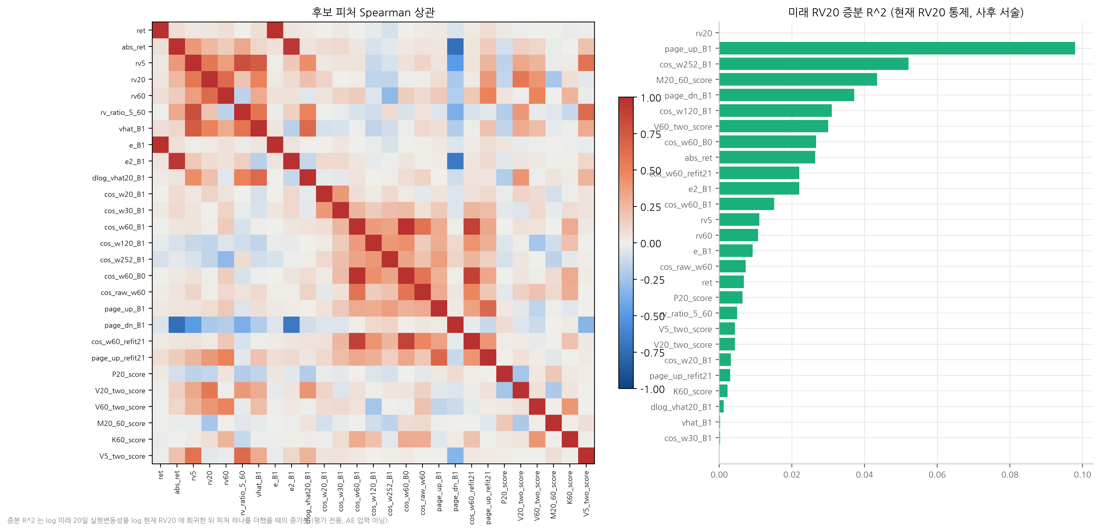

{"top_increment": {"cos_w252_B1": 0.0521, "page_up_B1": 0.098, "rv20": NaN}}


In [30]:
display(Image(data=preview(FIGDIR / "F09_AE_피처_중복성.png")))  # 저장된 PNG(320dpi)의 축소 미리보기
print(json.dumps(CAP.get("F09_AE_피처_중복성", {}), ensure_ascii=False, default=str)[:600])  # 캡션 수치 (결과 파일에서 계산)

## 10. 결론 · 한계 · 다음 실험

**결론 — 연구 질문에 대한 답.**
1. **CUSUM 구조.** 연도 관통(B1)은 통계량을 바꾸지 않고 커버리지만 늘린다 — 연초 초기화를 유지할 이유가 없다. 긴 창은 과거 변화를 최대 w 일 기억한다. Page 는 정책 A 잔차의 척도 오차 때문에 그대로는 쓸 수 없고, 자기정규화(X1) 로 하루 극단에 강해진다.
2. **SVR 정책.** 재학습 빈도·변화점 재학습의 예측 이득은 2020 한 해에 몰려 있고 2021–2025 에서는 없다. 짧은 학습창은 나쁘다. 재학습은 잔차 척도에 단절을 만들어 CUSUM 거짓 경보를 낳을 수 있다 (X-D6).
3. **검출력.** 군집이 있는 현실적 귀무에서, 같은 오경보 부담으로는 **어떤 구조도 지속형 분산 변화(×1.5–×3)를 크기 이상으로 잡지 못했다** (`LOW_POWER_INCONCLUSIVE`). 정책 A 의 빠른 적응이 변화를 예측분산으로 흡수한다. 하루 극단 충격과 분산 감소만 구별된다.
4. **AE 가치.** 경보·p 값이 아니라 **연속 통계량**(여러 창 CoS, 원수익률 CoS, Page 하방, 자기정규화 Page, 변화점 점수, 예측분산) 은 서로 중복이 낮고 일부는 미래 변동성에 증분 정보를 준다 → AE 입력 가치가 있다. 단 관측 귀무 부적합 때문에 '유의함' 표시는 넘기지 않는다.

**한계.** 합성 평가는 SVR 파이프라인 5종(B1·63일·21일 재학습·직전 252일·변화점 재학습)만 — 직전 504·756일, 유예 20·60일, 적응형은 관측 서술뿐이다 (`NOT_IN_SYNTHETIC`). 069500 하나 · 2021–2025 사건 7개 · 귀무 부적합(관측 p 확증 불가) · 크기 오차 ±1–1.5%p · 시나리오당 200 경로 · X1·X9 는 사후 확장.

**다음 실험.** (a) X1 자기정규화 Page 를 다른 ETF·2026 맹검으로 사전 등록 검증 · (b) 재적합 경계에서 표본내 e² 로 재표준화 (X-D6 b) · (c) 정책 B(재귀 예측) 잔차로 흡수 정도 비교 (X5) · (d) 1500 경로 통합 보정으로 크기 오차 축소 · (e) AE 인계 피처로 급변 구간 재구성 실험.

## 11. CLAIMS 및 재현성 검증

In [31]:
# 해석 문단의 숫자를 결과 파일에서 다시 계산해 대조한다 (불일치면 실패).
CL = json.loads((BASE / "notebook_claims.json").read_text(encoding="utf-8"))  # (주장, 결과파일, 식, 기대값)
bad = {}  # 불일치 주장
for c in CL:  # 주장마다
    df = pd.read_csv(RES / c["file"]) if c["file"].endswith(".csv") else None  # 근거 결과표
    got = eval(c["expr"], {"df": df, "np": np, "pd": pd, "RES": RES})  # 결과표에서 다시 계산한 값
    got = round(float(got), c.get("round", 6)) if isinstance(got, (int, float, np.floating, np.integer)) else got  # 반올림 규칙
    if got != c["expected"]:  # 본문 수치와 다르면
        bad[c["claim"]] = (got, c["expected"])  # 기록
print(f"CLAIMS {len(CL) - len(bad)}/{len(CL)} 일치")  # 결과
assert not bad, bad  # 불일치가 있으면 해석 문단을 고쳐야 한다

CLAIMS 80/80 일치


In [32]:
# 00–11 보호 파일이 실행 뒤에도 같은지 다시 확인한다 (G8).
bad = [p for h, p in PROT if sha(ROOT / p) != h]  # 바뀐 보호 파일
assert not bad, f"보호 파일 변경: {bad[:5]}"  # 변경 금지
print("보호 파일", len(PROT), "개 불변 · 결과 CSV", len(R["written"]), "개 · PNG", len(list(FIGDIR.glob('*.png'))), "· SVG", len(list(FIGDIR.glob('*.svg'))))  # 산출물 수

보호 파일 651 개 불변 · 결과 CSV 19 개 · PNG 15 · SVG 15
